In [8]:
import torch
import math
import numpy as np

# ============================================================
# 0. Core Hyperparameter Configuration
# ============================================================
dt = 1/252
T = 1.0
r = 0.02
d, N, M = 25, 12, 25

num_paths_bounds = 8192 * 4
train_batch_size = 4096
warmup_steps_env = 0
global_seed = 1234

pgd_steps_core = 100
pgd_lr_core = 0.05

# Network architecture and boundary penalty settings
nn_hidden_layers = [64, 64]
lambda_wall_penalty = 5.0
phi_threshold_ratio = 0.03

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dtype = torch.float64

# ============================================================
# 1. Factor Process Parameters
# ============================================================
# alpha: long-run mean of factors
alpha = np.array([
    0.012, -0.015,  0.008,  0.021, -0.011,  0.014, -0.018,  0.009,  0.016, -0.022,
    0.011, -0.007,  0.019,  0.005, -0.014,  0.022, -0.009,  0.017, -0.013,  0.025,
    0.006, -0.020,  0.015, -0.010,  0.018
])

# beta: mean-reversion matrix (25x25)
beta = np.array([
    [ 1.300,  0.042, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001],
    [-0.051,  1.292,  0.038, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001],
    [ 0.001, -0.045,  1.283,  0.044, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002],
    [-0.002,  0.004, -0.048,  1.275,  0.039, -0.002,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003],
    [ 0.003, -0.001,  0.002, -0.055,  1.267,  0.041, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004],
    [-0.004,  0.003, -0.001,  0.002, -0.046,  1.258,  0.037, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004],
    [ 0.002, -0.004,  0.003, -0.001,  0.002, -0.052,  1.250,  0.045, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003],
    [-0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.049,  1.242,  0.035, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003],
    [ 0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.042,  1.233,  0.048, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001],
    [-0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.051,  1.225,  0.036, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001],
    [ 0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.044,  1.217,  0.043, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002],
    [-0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.047,  1.208,  0.039, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002],
    [ 0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.053,  1.200,  0.046, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004],
    [-0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.041,  1.192,  0.034, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004],
    [ 0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.050,  1.183,  0.042, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003],
    [-0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.046,  1.175,  0.038, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003],
    [ 0.001, -0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.054,  1.167,  0.047, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001],
    [-0.004,  0.001, -0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.043,  1.158,  0.040, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001],
    [ 0.003, -0.004,  0.001, -0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.052,  1.150,  0.045, -0.003,  0.001, -0.004,  0.003, -0.002],
    [-0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.049,  1.142,  0.036, -0.002,  0.004, -0.001,  0.002],
    [ 0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.045,  1.133,  0.043, -0.003,  0.001, -0.004],
    [-0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.056,  1.125,  0.038, -0.002,  0.004],
    [ 0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.047,  1.117,  0.041, -0.003],
    [-0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.051,  1.108,  0.037],
    [ 0.035, -0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.042,  1.100]
])

# Sigma_V: factor volatility matrix (25x25)
Sigma_V = np.array([
    [ 0.305,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002],
    [ 0.052,  0.304,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001],
    [-0.001,  0.052,  0.304,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004],
    [ 0.004, -0.001,  0.052,  0.303,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002],
    [-0.002,  0.004, -0.001,  0.052,  0.303,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003],
    [ 0.003, -0.002,  0.004, -0.001,  0.052,  0.302,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004],
    [-0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.302,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001],
    [ 0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.301,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003],
    [-0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.300,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002],
    [ 0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.300,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001],
    [-0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.299,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004],
    [ 0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.299,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002],
    [-0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.298,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003],
    [ 0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.297,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004],
    [-0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.297,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001],
    [ 0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.296,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003],
    [-0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.296,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002],
    [ 0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.295,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001],
    [-0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.295,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004],
    [ 0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.294,  0.047,  0.001, -0.004,  0.003, -0.002],
    [-0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.293,  0.047,  0.001, -0.004,  0.003],
    [ 0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.293,  0.047,  0.001, -0.004],
    [-0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.292,  0.047,  0.001],
    [ 0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.292,  0.047],
    [-0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.291]
])

radius = 1.0

# v0: initial factor state vector
v0 = [
    0.08, -0.06,  0.09, -0.07,  0.05, -0.08,  0.07, -0.05,  0.09, -0.06,
    0.08, -0.04,  0.07, -0.09,  0.06, -0.08,  0.05, -0.07,  0.08, -0.06,
    0.09, -0.05,  0.07, -0.08,  0.06
]

# ============================================================
# 2. Asset Drift and Volatility Parameters (mu_0, M_mu, sigma_0, Gamma)
# ============================================================
mu_0 = np.array([
    0.012, 0.013, 0.014, 0.015, 0.018, 0.068,
    0.070, 0.072, 0.075, 0.078, 0.022, 0.024
])

M_mu = np.array([
    [ 0.155,  0.002, -0.003,  0.142,  0.001, -0.002,  0.128,  0.003,  0.001, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002],
    [ 0.002,  0.152, -0.002,  0.001, -0.138,  0.003, -0.001,  0.125, -0.003,  0.001, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.004,  0.001, -0.002,  0.003, -0.001],
    [-0.003,  0.001,  0.148, -0.002,  0.002,  0.135,  0.001, -0.002,  0.122, -0.001,  0.002, -0.004,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001],
    [ 0.092,  0.002, -0.004,  0.001,  0.085,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.004,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.004, -0.002,  0.001, -0.003],
    [ 0.002,  0.095,  0.003, -0.002,  0.001,  0.088,  0.004, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.004,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.004],
    [ 0.028, -0.024,  0.024,  0.001, -0.002,  0.001, -0.003,  0.002,  0.001, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002],
    [-0.024,  0.030, -0.028,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001],
    [ 0.028, -0.024,  0.024, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002],
    [-0.030,  0.024, -0.028,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001],
    [ 0.024, -0.030,  0.024, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001],
    [ 0.002, -0.001,  0.090,  0.003, -0.001,  0.002,  0.082,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002],
    [-0.002,  0.003, -0.001,  0.088, -0.003,  0.002, -0.001,  0.084, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001]
])


# sigma_0 in R^{N x M} (12x25): row-wise collinear mixing with norm preservation
sigma_0_raw = np.array([
    [ 0.145, -0.012,  0.018, -0.009,  0.015, -0.011,  0.014, -0.007,  0.012, -0.016,  0.009, -0.013,  0.015, -0.011,  0.008, -0.014,  0.012, -0.009,  0.015, -0.011,  0.008, -0.014,  0.012, -0.009,  0.015],
    [-0.014,  0.152, -0.011,  0.016, -0.013,  0.008, -0.015,  0.012, -0.009,  0.014, -0.011,  0.015, -0.008,  0.014, -0.012,  0.009, -0.016,  0.011, -0.014,  0.013, -0.009,  0.015, -0.011,  0.013, -0.008],
    [ 0.016, -0.009,  0.138, -0.014,  0.011, -0.015,  0.008, -0.013,  0.015, -0.011,  0.014, -0.009,  0.012, -0.016,  0.011, -0.008,  0.014, -0.012,  0.009, -0.015,  0.011, -0.013,  0.008, -0.016,  0.012],
    [-0.011,  0.015, -0.013,  0.161, -0.009,  0.012, -0.016,  0.011, -0.008,  0.015, -0.013,  0.011, -0.009,  0.014, -0.015,  0.012, -0.008,  0.016, -0.011,  0.009, -0.014,  0.012, -0.015,  0.011, -0.009],
    [ 0.013, -0.014,  0.008, -0.012,  0.149, -0.011,  0.015, -0.009,  0.014, -0.013,  0.008, -0.016,  0.011, -0.009,  0.015, -0.013,  0.011, -0.014,  0.008, -0.016,  0.012, -0.009,  0.015, -0.011,  0.013],
    [-0.009,  0.012, -0.015,  0.011, -0.013,  0.155, -0.008,  0.014, -0.011,  0.009, -0.015,  0.012, -0.014,  0.008, -0.016,  0.011, -0.009,  0.015, -0.013,  0.011, -0.008,  0.016, -0.012,  0.009, -0.014],
    [ 0.015, -0.011,  0.009, -0.016,  0.012, -0.008,  0.142, -0.013,  0.015, -0.009,  0.011, -0.014,  0.008, -0.015,  0.012, -0.007,  0.016, -0.011,  0.009, -0.014,  0.013, -0.008,  0.015, -0.012,  0.009],
    [-0.012,  0.016, -0.011,  0.008, -0.015,  0.013, -0.009,  0.158, -0.012,  0.016, -0.011,  0.009, -0.015,  0.013, -0.008,  0.014, -0.012,  0.009, -0.016,  0.011, -0.015,  0.009, -0.013,  0.016, -0.011],
    [ 0.009, -0.013,  0.016, -0.011,  0.008, -0.014,  0.012, -0.015,  0.136, -0.011,  0.016, -0.008,  0.013, -0.012,  0.009, -0.015,  0.011, -0.014,  0.012, -0.008,  0.016, -0.011,  0.009, -0.015,  0.013],
    [-0.015,  0.008, -0.014,  0.012, -0.009,  0.016, -0.011,  0.008, -0.014,  0.164, -0.012,  0.015, -0.009,  0.014, -0.011,  0.008, -0.016,  0.013, -0.009,  0.015, -0.011,  0.014, -0.012,  0.008, -0.016],
    [ 0.011, -0.015,  0.009, -0.013,  0.016, -0.011,  0.008, -0.014,  0.012, -0.016,  0.147, -0.011,  0.009, -0.015,  0.012, -0.016,  0.011, -0.008,  0.014, -0.012,  0.009, -0.016,  0.011, -0.014,  0.008],
    [-0.008,  0.014, -0.012,  0.009, -0.015,  0.011, -0.016,  0.012, -0.009,  0.015, -0.013,  0.151, -0.014,  0.011, -0.008,  0.015, -0.012,  0.009, -0.016,  0.011, -0.014,  0.008, -0.015,  0.012, -0.009]
])

n0 = np.linalg.norm(sigma_0_raw, axis=1, keepdims=True)
sigma_0_new = np.copy(sigma_0_raw)
for i in range(N):
    if i > 0:
        sigma_0_new[i] += 0.35 * sigma_0_raw[i-1]
    if i < N - 1:
        sigma_0_new[i] += 0.35 * sigma_0_raw[i+1]
n1 = np.linalg.norm(sigma_0_new, axis=1, keepdims=True)
sigma_0 = sigma_0_new * (n0 / np.maximum(n1, 1e-12))


Gamma = np.array([
    [ 0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.028,  0.002, -0.001,  0.003, -0.002,  0.001,  0.022, -0.002,  0.001, -0.003,  0.002, -0.001,  0.014,  0.002, -0.003,  0.001, -0.002],
    [-0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002,  0.028, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003,  0.022, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003],
    [ 0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.002,  0.028, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002,  0.022, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001],
    [-0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.028,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002,  0.022, -0.003,  0.001, -0.002,  0.014,  0.003, -0.001,  0.002],
    [ 0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.028,  0.001, -0.002,  0.003,  0.022, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001],
    [-0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001,  0.028, -0.002,  0.003, -0.001,  0.002,  0.022, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002],
    [ 0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003,  0.028, -0.001,  0.002, -0.003,  0.001,  0.022, -0.002,  0.003, -0.001,  0.002, -0.003,  0.014,  0.001, -0.002],
    [-0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.028,  0.002, -0.003,  0.001, -0.002,  0.003,  0.022, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001],
    [ 0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.028,  0.001, -0.002,  0.003, -0.001,  0.002,  0.022, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002],
    [-0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001,  0.028, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001,  0.022, -0.002,  0.003, -0.001,  0.014,  0.002],
    [ 0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003,  0.028, -0.001,  0.002, -0.003,  0.001,  0.022, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001],
    [-0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.028,  0.002, -0.003,  0.001, -0.002,  0.003,  0.022, -0.001,  0.002, -0.003,  0.001,  0.014]
])


rho_VS = np.array([
    [ 0.090,  0.002, -0.003, -0.090,  0.001, -0.002,  0.090,  0.002, -0.001, -0.090,  0.003, -0.002,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002],
    [ 0.002,  0.090, -0.002,  0.001, -0.090,  0.003, -0.001,  0.090,  0.002, -0.003, -0.090,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002],
    [-0.003,  0.001,  0.090, -0.002,  0.003, -0.090,  0.002, -0.001,  0.090,  0.001, -0.002, -0.090,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003],
    [ 0.090, -0.002,  0.001,  0.003, -0.001,  0.090, -0.003,  0.002, -0.002,  0.001,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002],
    [ 0.001,  0.090, -0.003,  0.002,  0.003, -0.001,  0.090, -0.002,  0.001, -0.003,  0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003],
    [-0.002,  0.003,  0.090, -0.001,  0.002,  0.001, -0.003,  0.090,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001],
    [ 0.003, -0.001,  0.002,  0.090, -0.002,  0.003,  0.001, -0.001,  0.090,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002],
    [-0.001,  0.002, -0.003,  0.001,  0.090, -0.002,  0.003,  0.001, -0.002,  0.003,  0.001,  0.090,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002],
    [ 0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002],
    [-0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003],
    [ 0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001],
    [-0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002],
    [ 0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003],
    [-0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001],
    [ 0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002],
    [-0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003],
    [ 0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001],
    [-0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002],
    [ 0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003],
    [-0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001],
    [ 0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002],
    [-0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003],
    [ 0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001],
    [-0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002],
    [ 0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003]
])


# Construct joint correlation matrix from rho_VS
corr_matrix = np.block([
    [np.eye(d),      rho_VS],
    [rho_VS.T,       np.eye(M)]
])
evals = np.linalg.eigvalsh(corr_matrix)
if evals.min() <= 0:
    raise ValueError("Correlation matrix is not positive definite; check rho_VS magnitude.")
np.fill_diagonal(corr_matrix, 1.0)

# ============================================================
# 4. Pack Calibrated Parameters Dictionary
# ============================================================
calibrated_params = {
    'r': float(r),
    'mu_base': mu_0.astype(np.float64),
    'mu_load': M_mu.astype(np.float64),
    'sigma_0': sigma_0.astype(np.float64),
    'gamma_mat': Gamma.astype(np.float64),
    'corr_matrix': corr_matrix.tolist(),
    'sigma_V': Sigma_V.astype(np.float64).tolist(),
    'radius': float(radius)
}

In [9]:
import time
import math
import torch
import numpy as np
import matplotlib.pyplot as plt

from StateDependentAssetModel_GPU import StateDependentAssetModel_GPU
from LambdaNetwork import LambdaNetwork
from lnSRE_Equation_plus import lnSRE_Equation_plus
from lnSRE_Equation_minus import lnSRE_Equation_minus
from OnlineDeepLnSRESolver import OnlineDeepLnSRESolver


class IndependentSREEvaluator:
    """
    Out-of-Sample (OOS) independent evaluator and GPU-accelerated quantile funnel plotter.
    - Adapted to LambdaNetwork interface: forward(step_idx, V_t, rho_v)
    - Automatically queries solver._compute_physical_prior_rho(V_t)
    - Incorporates Skorokhod reflection displacement Xi for local-time compensation
    """
    def __init__(self, solver, simulator, device='cpu'):
        """
        :param solver: Instantiated OnlineDeepLnSRESolver
        :param simulator: Instantiated StateDependentAssetModel_GPU
        """
        self.solver = solver
        self.simulator = simulator
        self.device = torch.device(device)

    @torch.no_grad()
    def execute_audit(self, model_path, v0, num_scenarios=20000, seed=9999):
        """
        Load model checkpoint, simulate independent out-of-sample paths, and evaluate terminal statistics.
        """
        # 1. Load model checkpoint and switch to evaluation mode
        self.solver.load_model(file_path=model_path)
        self.solver.lambda_net.eval()
        self.solver.sre_equation.eval()

        # Extract clamped initial value in log-space
        check_p0_value = torch.clamp(
            self.solver.P0,
            min=self.solver.log_p_lower,
            max=self.solver.log_p_upper
        ).item()

        print(f"\n>>> [Auditor] Starting OOS evaluation | Scenarios: {num_scenarios:,} | Seed: {seed}")

        # 2. Update simulator path count and generate independent trajectories
        self.simulator.num_paths = num_scenarios
        t0 = time.time()

        V_time_first, _, dW_time_first, Xi_time_first = self.simulator.simulate(
            v0=v0, return_full_path=True, auto_analyze=False, verbose=False, seed=seed
        )
        t1 = time.time()
        print(f"    • OOS trajectories generated in {t1 - t0:.4f} s.")

        # 3. Cast to float64 and transpose to (num_scenarios, time, dim)
        V_test = V_time_first.transpose(0, 1).contiguous().to(self.device, dtype=torch.float64)
        dW_test = dW_time_first.transpose(0, 1).contiguous().to(self.device, dtype=torch.float64)
        Xi_test = Xi_time_first.transpose(0, 1).contiguous().to(self.device, dtype=torch.float64)

        n_steps = self.solver.N_steps

        check_P_history = torch.zeros((num_scenarios, n_steps + 1), dtype=torch.float64, device=self.device)
        check_P_history[:, 0] = check_p0_value
        check_P_t = torch.full((num_scenarios, 1), check_p0_value, dtype=torch.float64, device=self.device)

        # 4. Forward numerical integration
        t2 = time.time()
        for i in range(n_steps):
            V_curr = V_test[:, i, :]
            dW_curr = dW_test[:, i, :]
            delta_xi_curr = Xi_test[:, i, :]

            # Compute physical prior rho_v and pass to step-specific sub-network
            rho_v = self.solver._compute_physical_prior_rho(V_curr)
            out = self.solver.lambda_net(i, V_curr, rho_v)
            check_Lambda_t = out[0] if isinstance(out, tuple) else out

            if check_Lambda_t.shape[1] < dW_curr.shape[1]:
                zeros = torch.zeros(
                    check_Lambda_t.shape[0],
                    dW_curr.shape[1] - check_Lambda_t.shape[1],
                    dtype=check_Lambda_t.dtype,
                    device=check_Lambda_t.device
                )
                check_Lambda_full = torch.cat([check_Lambda_t, zeros], dim=1)
            else:
                check_Lambda_full = check_Lambda_t

            # Compute drift and diffusion terms
            drift = self.solver.sre_equation(i * self.solver.dt, check_P_t, check_Lambda_full, V_curr)
            diffusion_term = torch.sum(check_Lambda_full * dW_curr, dim=1, keepdim=True)

            # Skorokhod reflection compensation
            check_Lambda_active = check_Lambda_full[:, :self.solver.d_dim]
            grad_P = torch.matmul(check_Lambda_active, self.solver.inv_sigma_V)
            skorokhod_comp = torch.sum(grad_P * delta_xi_curr, dim=1, keepdim=True)

            check_P_t = check_P_t + drift * self.solver.dt + diffusion_term + skorokhod_comp
            check_P_history[:, i + 1] = check_P_t.squeeze(-1)

        t3 = time.time()
        print(f"    • OOS forward integration completed in {t3 - t2:.4f} s.")

        # 5. Save results and print summary statistics
        self._cached_GPU_history = check_P_history
        check_P_history_np = check_P_history.cpu().numpy()
        check_P_T_pred = check_P_history_np[:, -1]

        mean_yt = float(np.mean(check_P_T_pred))
        std_yt = float(np.std(check_P_T_pred))
        mse_loss = float(np.mean((check_P_T_pred - 0.0) ** 2))
        max_deviation = float(np.max(np.abs(check_P_history_np - 0.0)))

        print("\n" + "=" * 80)
        print(" [ Log-Space SRE Out-of-Sample Evaluation Report ]")
        print("=" * 80)
        print(f"  • Total OOS Scenarios : {num_scenarios:<10d} | Time Steps : {n_steps}")
        print("-" * 80)
        print(f"  • Initial Value       : check_P(0) = {check_p0_value:+10.6f} (Physical P(0) = {math.exp(check_p0_value):.6f})")
        print(f"  • Terminal Statistics (Target = 0.000000):")
        print(f"    - Terminal Mean               : {mean_yt:+12.6f}")
        print(f"    - Terminal Std                : {std_yt:12.6f}")
        print(f"    - Terminal MSE                : {mse_loss:12.4e}")
        print(f"  • Maximum Absolute Deviation    : {max_deviation:12.4f}")
        print("=" * 80 + "\n")

        return check_P_history_np, check_p0_value

    def plot_funnel(self, check_P_history=None):
        """
        Plot out-of-sample quantile funnel distribution on GPU.
        """
        if hasattr(self, '_cached_GPU_history'):
            history_tensor = self._cached_GPU_history
        else:
            if check_P_history is None:
                raise ValueError("Provide check_P_history or call execute_audit() first.")
            history_tensor = torch.as_tensor(check_P_history, device=self.device, dtype=torch.float64)

        num_scenarios, n_steps_plus_1 = history_tensor.shape
        time_grid = np.linspace(0, self.solver.T, n_steps_plus_1)

        # Parallel quantile computation on GPU
        p_min = torch.amin(history_tensor, dim=0).cpu().numpy()
        p_max = torch.amax(history_tensor, dim=0).cpu().numpy()

        pct_tensors = torch.tensor([0.01, 0.10, 0.90, 0.99], device=self.device, dtype=torch.float64)
        quantiles_gpu = torch.quantile(history_tensor, pct_tensors, dim=0)
        quantiles = quantiles_gpu.cpu().numpy()

        p_01, p_10, p_90, p_99 = quantiles[0], quantiles[1], quantiles[2], quantiles[3]
        p_mean = torch.mean(history_tensor, dim=0).cpu().numpy()

        fig, ax = plt.subplots(figsize=(12, 7), dpi=150)

        ax.fill_between(time_grid, p_min, p_max, color='#1f77b4', alpha=0.08, label='Absolute Range (Min-Max)')
        ax.fill_between(time_grid, p_01, p_99, color='#1f77b4', alpha=0.20, label='98% Interval (1st-99th Pct)')
        ax.fill_between(time_grid, p_10, p_90, color='#1f77b4', alpha=0.35, label='80% Interval (10th-90th Pct)')

        ax.plot(time_grid, p_mean, color='#d62728', linewidth=2.5, label=r'Empirical Mean $\mathbb{E}[\check{P}_+(t)]$')
        ax.axhline(y=0.0, color='#2ca02c', linestyle='--', linewidth=2.0, label=r'Theoretical Target ($\check{P}_+(T) = 0.0$)')

        ax.set_title(
            fr'Log-Space Distribution Evolution of $\check{{P}}_+(t)$ ({num_scenarios:,} Out-of-Sample Scenarios)',
            fontsize=14, fontweight='bold', pad=12
        )
        ax.set_xlabel('Time $t$', fontsize=11)
        ax.set_ylim(-0.5, 0.5)
        ax.set_ylabel(r'Log State Value $\check{P}_+(t)$', fontsize=11)
        ax.grid(True, linestyle=':', alpha=0.5)
        ax.legend(loc='upper left', fontsize=11, framealpha=0.95)

        plt.tight_layout()
        plt.show()




[System] Initialized Log-Space Online Solver (with Skorokhod Compensation)
---------------------------------------------------------------------------
 • Initial log value check_P(0)         :   +0.000000
 • Initial physical value P(0)          :   1.000000
 • lambda_wall (boundary penalty weight): 5.0
 • phi_threshold (projection threshold) : 0.0300

>>> [Model Loaded] Restored checkpoint state! Current progress: Epoch 1246
 • check_P(0) =  -0.066315 (P(0) =   0.935836)

>>> [Auditor] Starting OOS evaluation | Scenarios: 30,000 | Seed: 8888
    • OOS trajectories generated in 0.4969 s.
    • OOS forward integration completed in 19.1427 s.

 [ Log-Space SRE Out-of-Sample Evaluation Report ]
  • Total OOS Scenarios : 30000      | Time Steps : 252
--------------------------------------------------------------------------------
  • Initial Value       : check_P(0) =  -0.066315 (Physical P(0) = 0.935836)
  • Terminal Statistics (Target = 0.000000):
    - Terminal Mean               :    +0

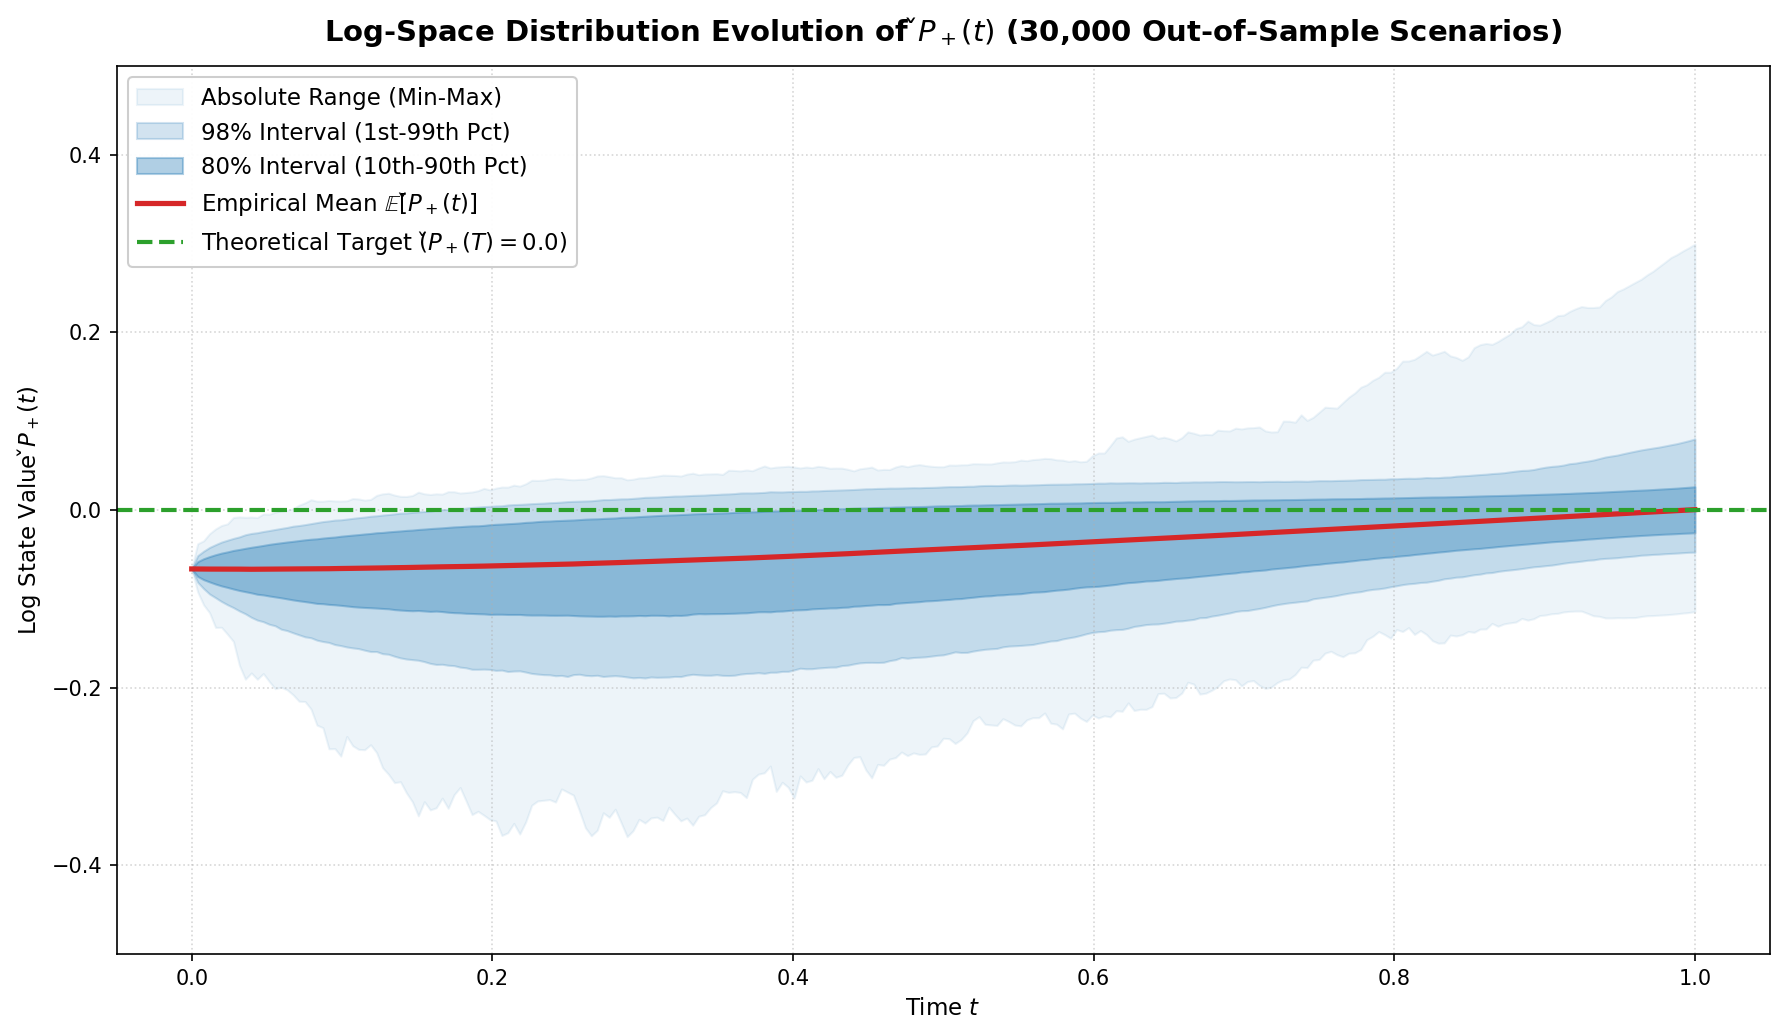

In [10]:

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dtype = torch.float64

env_generator = StateDependentAssetModel_GPU(
    d_dim=d, N_dim=N, M_dim=M,
    alpha=alpha, beta=beta, sigma_V=Sigma_V, radius=radius,
    mu_base=mu_0, mu_load=M_mu, sigma_0=sigma_0, gamma_mat=Gamma,
    corr_matrix=corr_matrix.tolist(),
    dt=dt, T=T, num_paths=train_batch_size, warmup_steps=0,
    device=device
)

lambda_net = LambdaNetwork(
    num_steps=int(T / dt),
    d_dim=int(d),
    M_dim=int(M),
    radius=radius,
    hidden_layers=nn_hidden_layers
).to(device=device, dtype=dtype)

sre_eq = lnSRE_Equation_plus(
    params=calibrated_params,
    device=device,
    pgd_steps=pgd_steps_core,
    pgd_lr_base=pgd_lr_core
).to(device=device, dtype=dtype)

solver = OnlineDeepLnSRESolver(
    params=calibrated_params,
    lambda_net=lambda_net,
    sre_equation=sre_eq,
    dt=float(dt),
    T=float(T),
    device=device,
    initial_p0=0.0,
    p_lower=0.1,
    p_upper=10.0,
    lambda_wall=lambda_wall_penalty,
    phi_threshold=phi_threshold_ratio * radius
)

evaluator = IndependentSREEvaluator(solver=solver, simulator=env_generator, device=device)

check_P_hist, p0_val = evaluator.execute_audit(
    model_path='OU_P_plus.pt',
    v0=v0,
    num_scenarios=30000,
    seed=8888
)

evaluator.plot_funnel(check_P_history=check_P_hist)

[System] Initialized Log-Space Online Solver (with Skorokhod Compensation)
---------------------------------------------------------------------------
 • Initial log value check_P(0)         :   +0.000000
 • Initial physical value P(0)          :   1.000000
 • lambda_wall (boundary penalty weight): 5.0
 • phi_threshold (projection threshold) : 0.0300

>>> [Model Loaded] Restored checkpoint state! Current progress: Epoch 1258
 • check_P(0) =  -0.347042 (P(0) =   0.706775)

>>> [Auditor] Starting OOS evaluation | Scenarios: 30,000 | Seed: 8888
    • OOS trajectories generated in 0.4409 s.
    • OOS forward integration completed in 22.0057 s.

 [ Log-Space SRE Out-of-Sample Evaluation Report ]
  • Total OOS Scenarios : 30000      | Time Steps : 252
--------------------------------------------------------------------------------
  • Initial Value       : check_P(0) =  -0.347042 (Physical P(0) = 0.706775)
  • Terminal Statistics (Target = 0.000000):
    - Terminal Mean               :    +0

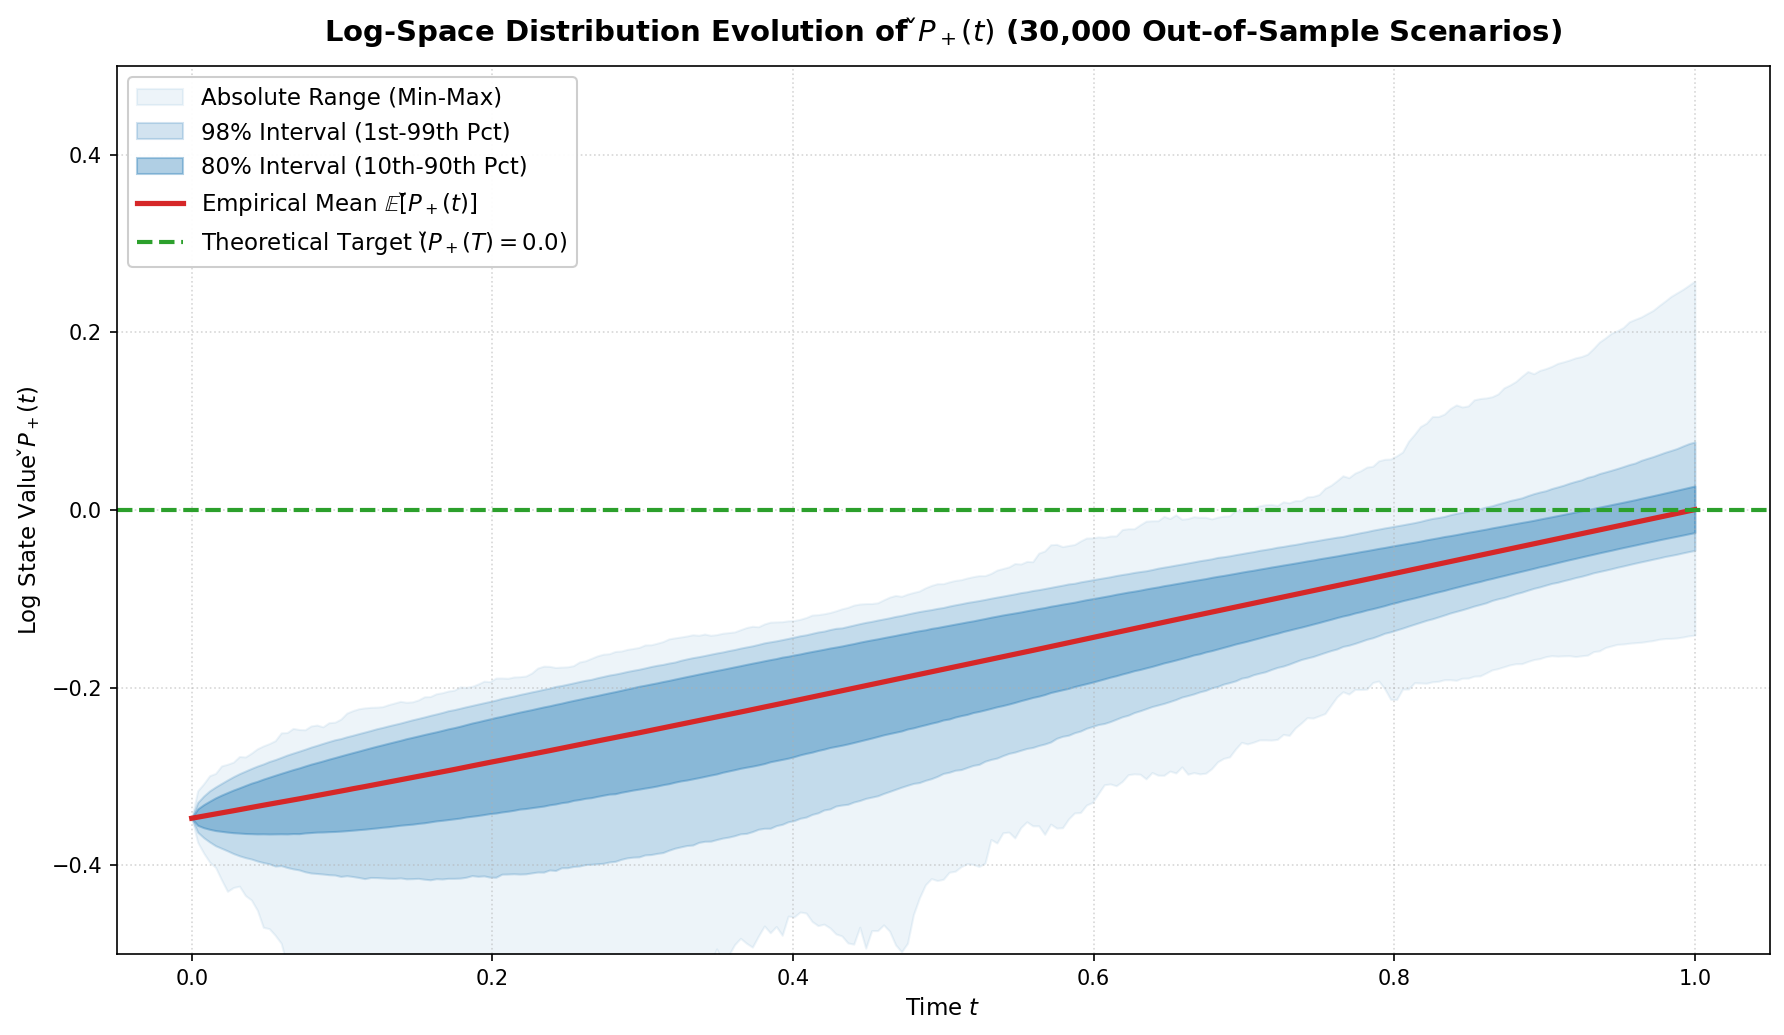

In [11]:

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dtype = torch.float64

env_generator = StateDependentAssetModel_GPU(
    d_dim=d, N_dim=N, M_dim=M,
    alpha=alpha, beta=beta, sigma_V=Sigma_V, radius=radius,
    mu_base=mu_0, mu_load=M_mu, sigma_0=sigma_0, gamma_mat=Gamma,
    corr_matrix=corr_matrix.tolist(),
    dt=dt, T=T, num_paths=train_batch_size, warmup_steps=0,
    device=device
)

lambda_net = LambdaNetwork(
    num_steps=int(T / dt),
    d_dim=int(d),
    M_dim=int(M),
    radius=radius,
    hidden_layers=nn_hidden_layers
).to(device=device, dtype=dtype)

sre_eq = lnSRE_Equation_minus(
    params=calibrated_params,
    device=device,
    pgd_steps=pgd_steps_core,
    pgd_lr_base=pgd_lr_core
).to(device=device, dtype=dtype)

solver = OnlineDeepLnSRESolver(
    params=calibrated_params,
    lambda_net=lambda_net,
    sre_equation=sre_eq,
    dt=float(dt),
    T=float(T),
    device=device,
    initial_p0=0.0,
    p_lower=0.1,
    p_upper=10.0,
    lambda_wall=lambda_wall_penalty,
    phi_threshold=phi_threshold_ratio * radius
)

evaluator = IndependentSREEvaluator(solver=solver, simulator=env_generator, device=device)

check_P_hist, p0_val = evaluator.execute_audit(
    model_path='OU_P_minus.pt',
    v0=v0,
    num_scenarios=30000,
    seed=8888
)

evaluator.plot_funnel(check_P_history=check_P_hist)